In [1]:
# ==============================================================================
# ⚙️ CENTRALIZED TRAINING PARAMETERS & CONFIGURATION
# ==============================================================================
import os
import glob
import time
import math
import copy
import random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from PIL import Image

# Enable CUDA 
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch Version:", torch.__version__)
print("Active Device:  ", device)
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    total_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU Hardware:   {gpu_name} ({total_mem:.2f} GB VRAM)")

PyTorch Version: 2.11.0+cu126
Active Device:   cuda
GPU Hardware:   NVIDIA GeForce RTX 3050 Ti Laptop GPU (4.00 GB VRAM)


In [2]:
# ------------------------------------------------------------------------------
# 1. Dataset & Image Dimensions
# ------------------------------------------------------------------------------
DATASET_PATH = r"C:\Users\MADHUSHALNE\DATASET ML\140K Real and Fake Faces dataset\real_vs_fake\real-vs-fake"
IMG_SIZE = 256                    # Native 256x256 resolution (No resizing needed)

# ------------------------------------------------------------------------------
# 2. DataLoader & Hardware Acceleration
# ------------------------------------------------------------------------------
BATCH_SIZE = 256                  # Batch size 256 to saturate GPU VRAM & CUDA cores
NUM_WORKERS = 4                   # 4 CPU worker threads preloading RAM
PIN_MEMORY = True                 # Fast page-locked CPU -> GPU memory transfers
PERSISTENT_WORKERS = True         # Keep worker threads warm between epochs
PREFETCH_FACTOR = 2               # Pre-fetch 2 batches per CPU worker
6
# ------------------------------------------------------------------------------
# 3. Dataset Partitioning & Training Budget
# ------------------------------------------------------------------------------
TRAIN_SAMPLES_PER_CLASS = 10000   # 10,000 real + 10,000 fake = 20,000 training images per epoch
NUM_EPOCHS = 5                    # Number of training epochs

# ------------------------------------------------------------------------------
# 4. Model & Optimization Hyperparameters
# ------------------------------------------------------------------------------
LR_FEATURES = 1e-4                # Learning rate for top unfrozen conv blocks
LR_CLASSIFIER = 1e-3              # Learning rate for the classification head
WEIGHT_DECAY = 1e-4               # AdamW weight decay regularizer
DROPOUT_RATE = 0.3                # Dropout rate before final linear layer

# ------------------------------------------------------------------------------
# 5. Checkpoints & Export Paths
# ------------------------------------------------------------------------------
CHECKPOINT_DIR = "checkpoints"    # Folder to store checkpoints
MODEL_SAVE_PATH = "deepfake_detection_model.pth"        # Final model package with metadata
ENTIRE_MODEL_SAVE_PATH = "deepfake_detector_entire_model.pt" # Full serialized PyTorch model
RESUME = True                     # Set True to resume from latest saved checkpoint
# ==============================================================================



In [3]:
# Training transforms with native 256x256 tensor conversion (NO resize overhead)
train_transforms = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Validation transforms (direct tensor normalization)
valid_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = datasets.ImageFolder(os.path.join(DATASET_PATH, "train"), transform=train_transforms)
valid_full = datasets.ImageFolder(os.path.join(DATASET_PATH, "valid"), transform=valid_transforms)

print(f"Found {len(train_full):,} raw training images and {len(valid_full):,} validation images.")
print(f"Class mapping: {train_full.class_to_idx}")

Found 100,000 raw training images and 20,000 validation images.
Class mapping: {'fake': 0, 'real': 1}


In [4]:
def create_balanced_subset(dataset, samples_per_class, seed=42):
    np.random.seed(seed)
    class_indices = {}
    for idx, (_, label) in enumerate(dataset.samples):
        if label not in class_indices:
            class_indices[label] = []
        class_indices[label].append(idx)
        
    subset_indices = []
    for label, indices in class_indices.items():
        n = min(len(indices), samples_per_class)
        selected = np.random.choice(indices, size=n, replace=False)
        subset_indices.extend(selected)
        
    np.random.shuffle(subset_indices)
    return Subset(dataset, subset_indices)


train_dataset = create_balanced_subset(train_full, TRAIN_SAMPLES_PER_CLASS)
print(f"[+] Balanced Training Subset: {len(train_dataset):,} images ({TRAIN_SAMPLES_PER_CLASS:,} per class)")


valid_dataset = valid_full

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY if torch.cuda.is_available() else False,
    persistent_workers=PERSISTENT_WORKERS if NUM_WORKERS > 0 else False,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY if torch.cuda.is_available() else False,
    persistent_workers=PERSISTENT_WORKERS if NUM_WORKERS > 0 else False,
    prefetch_factor=PREFETCH_FACTOR if NUM_WORKERS > 0 else None
)

print(f"DataLoaders active: Train={len(train_loader)} batches | Valid={len(valid_loader)} batches (Batch Size={BATCH_SIZE})")

[+] Balanced Training Subset: 20,000 images (10,000 per class)
DataLoaders active: Train=79 batches | Valid=79 batches (Batch Size=256)


In [5]:
#  MODEL
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)
for i, block in enumerate(model.features):
    print(f"\nBLOCK {i}")
    print(block)
    


BLOCK 0
Conv2dNormActivation(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): SiLU(inplace=True)
)

BLOCK 1
Sequential(
  (0): MBConv(
    (block): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): SqueezeExcitation(
        (avgpool): AdaptiveAvgPool2d(output_size=1)
        (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
        (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
        (activation): SiLU(inplace=True)
        (scale_activation): Sigmoid()
      )
      (2): Conv2dNormActivation(
        (0): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(16, eps=1e-

In [6]:

# Freeze lower feature extractor blocks
for param in model.features[:5].parameters():
    param.requires_grad = False

# Unfreeze top feature blocks for deep domain fine-tuning
for param in model.features[5:].parameters():
    param.requires_grad = True

# Custom classifier head
num_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(p=DROPOUT_RATE, inplace=True),
    nn.Linear(num_features, 2)
)

model = model.to(device)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"Model: EfficientNet-B0 (Fine-Tuning Active)")
print(f"Trainable Parameters: {trainable_params:,} / {total_params:,} ({(trainable_params/total_params)*100:.1f}%)")

Model: EfficientNet-B0 (Fine-Tuning Active)
Trainable Parameters: 3,701,450 / 4,010,110 (92.3%)


In [7]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW([
    {'params': model.features[5:].parameters(), 'lr': LR_FEATURES, 'weight_decay': WEIGHT_DECAY},
    {'params': model.classifier.parameters(), 'lr': LR_CLASSIFIER, 'weight_decay': WEIGHT_DECAY}
])

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=1
)

scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())
print(f"Optimizer: AdamW (LR Conv: {LR_FEATURES}, LR Classifier: {LR_CLASSIFIER}) | Mixed Precision: {torch.cuda.is_available()}")

Optimizer: AdamW (LR Conv: 0.0001, LR Classifier: 0.001) | Mixed Precision: True


C:\Users\MADHUSHALNE\AppData\Local\Temp\ipykernel_25324\1894831438.py:15: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=torch.cuda.is_available())


In [8]:
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

def save_checkpoint(state, is_best, epoch, checkpoint_dir=CHECKPOINT_DIR):
    os.makedirs(checkpoint_dir, exist_ok=True)
    epoch_path = os.path.join(checkpoint_dir, f"checkpoint_epoch_{epoch}.pth")
    torch.save(state, epoch_path)
    
    last_path = os.path.join(checkpoint_dir, "last_checkpoint.pth")
    torch.save(state, last_path)
    
    if is_best:
        best_path = os.path.join(checkpoint_dir, "best_model.pth")
        torch.save(state, best_path)
        print(f"  [*] BEST MODEL UPDATED! (Val Acc: {state['val_acc']*100:.2f}%)")
        
    print(f"  [+] Checkpoint saved: {epoch_path}")

def find_latest_checkpoint(checkpoint_dir=CHECKPOINT_DIR):
    last_path = os.path.join(checkpoint_dir, "last_checkpoint.pth")
    if os.path.exists(last_path):
        return last_path
    epoch_files = glob.glob(os.path.join(checkpoint_dir, "checkpoint_epoch_*.pth"))
    if not epoch_files:
        return None
    def extract_epoch(f):
        try:
            return int(os.path.basename(f).replace("checkpoint_epoch_", "").replace(".pth", ""))
        except:
            return -1
    epoch_files.sort(key=extract_epoch)
    return epoch_files[-1]

def load_checkpoint(checkpoint_path, model, optimizer=None, scheduler=None, scaler=None):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Checkpoint not found: {checkpoint_path}")
        
    print(f"Loading checkpoint: {checkpoint_path}")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    
    model.load_state_dict(checkpoint['model_state_dict'])
    if optimizer and 'optimizer_state_dict' in checkpoint:
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    if scheduler and checkpoint.get('scheduler_state_dict'):
        scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    if scaler and checkpoint.get('scaler_state_dict'):
        scaler.load_state_dict(checkpoint['scaler_state_dict'])
        
    start_epoch = checkpoint['epoch'] + 1
    best_val_acc = checkpoint.get('best_val_acc', checkpoint.get('val_acc', 0.0))
    history = checkpoint.get('history', {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []})
    
    print(f"Resumed from Epoch {checkpoint['epoch']} | Best Val Acc: {best_val_acc*100:.2f}%")
    return start_epoch, best_val_acc, history

In [9]:
def train_one_epoch(model, dataloader, criterion, optimizer, scaler, device, epoch, num_epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()
    
    total_batches = len(dataloader)
    print_interval = max(1, total_batches // 5)
    
    for batch_idx, (images, labels) in enumerate(dataloader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        
        optimizer.zero_grad(set_to_none=True)
        
        with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
            outputs = model(images)
            loss = criterion(outputs, labels)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)
        
        if (batch_idx + 1) % print_interval == 0 or (batch_idx + 1) == total_batches:
            batch_acc = (correct / total) * 100
            current_loss = running_loss / total
            elapsed = time.time() - start_time
            print(f"  Epoch [{epoch}/{num_epochs}] | Batch [{batch_idx+1}/{total_batches}] | Loss: {current_loss:.4f} | Acc: {batch_acc:.2f}% | Elapsed: {elapsed:.1f}s")
            
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def validate(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            
            with torch.cuda.amp.autocast(enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, labels)
                
            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels.data).item()
            total += labels.size(0)
            
    val_loss = running_loss / total
    val_acc = correct / total
    return val_loss, val_acc

In [10]:
start_epoch = 1
best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

if RESUME:
    chk_to_load = find_latest_checkpoint(CHECKPOINT_DIR)
    if chk_to_load and os.path.exists(chk_to_load):
        start_epoch, best_val_acc, history = load_checkpoint(
            chk_to_load, model, optimizer, scheduler, scaler
        )
    else:
        print("[i] No checkpoint found. Starting fresh training run.")

print(f"\n{'='*60}")
print(f"TRAINING START: Epochs {start_epoch} to {NUM_EPOCHS}")
print(f"Device: {device} | Batch Size: {BATCH_SIZE} | Workers: {NUM_WORKERS} | Image: {IMG_SIZE}x{IMG_SIZE}")
print(f"{'='*60}\n")

total_train_start = time.time()

for epoch in range(start_epoch, NUM_EPOCHS + 1):
    epoch_start = time.time()
    print(f"\n>>> EPOCH [{epoch}/{NUM_EPOCHS}] START")
    
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, scaler, device, epoch, NUM_EPOCHS
    )
    
    val_loss, val_acc = validate(model, valid_loader, criterion, device)
    
    scheduler.step(val_loss)
    
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    
    is_best = val_acc > best_val_acc
    if is_best:
        best_val_acc = val_acc
        
    save_checkpoint({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'val_loss': val_loss,
        'val_acc': val_acc,
        'best_val_acc': best_val_acc,
        'history': history,
        'classes': train_full.classes,
        'img_size': IMG_SIZE
    }, is_best=is_best, epoch=epoch)
    
    epoch_time = time.time() - epoch_start
    print(f"\n--- EPOCH {epoch} SUMMARY ({epoch_time/60:.2f} min) ---")
    print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}%")
    print(f"  Valid Loss: {val_loss:.4f} | Valid Acc: {val_acc*100:.2f}% (Best: {best_val_acc*100:.2f}%)")
    print(f"  Current LR: {optimizer.param_groups[0]['lr']:.6f}")

total_elapsed = time.time() - total_train_start
print(f"\n{'='*60}")
print(f"TRAINING COMPLETE in {total_elapsed/60:.2f} minutes | Best Val Acc: {best_val_acc*100:.2f}%")
print(f"{'='*60}")

Loading checkpoint: checkpoints\last_checkpoint.pth
Resumed from Epoch 5 | Best Val Acc: 98.29%

TRAINING START: Epochs 6 to 5
Device: cuda | Batch Size: 256 | Workers: 4 | Image: 256x256


TRAINING COMPLETE in 0.00 minutes | Best Val Acc: 98.29%


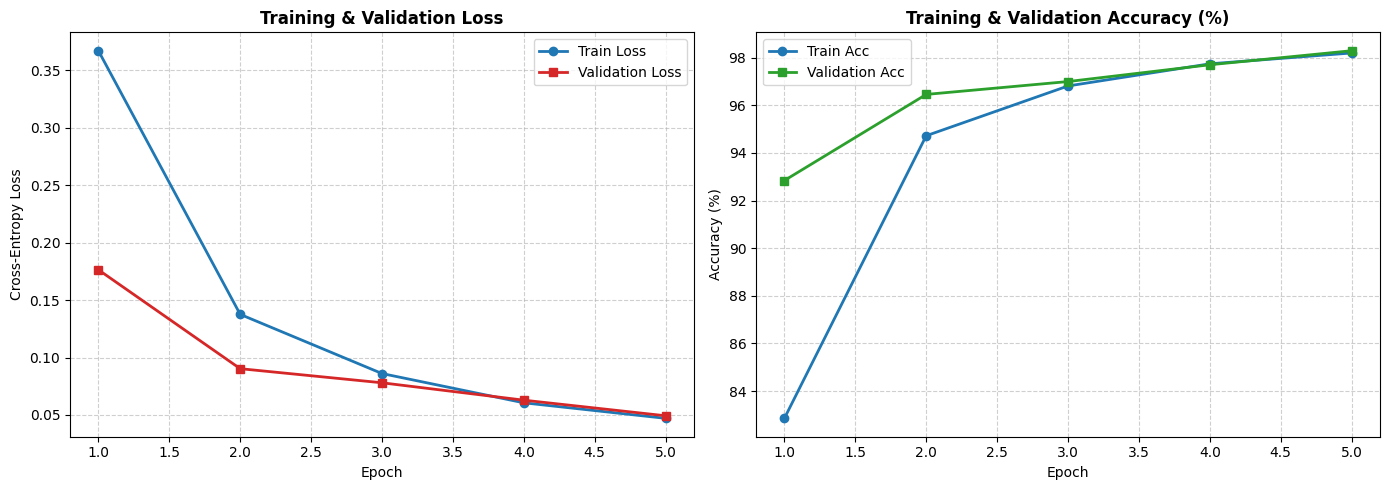

In [11]:
if len(history['train_loss']) > 0:
    epochs_range = range(1, len(history['train_loss']) + 1)
    
    plt.figure(figsize=(14, 5))
    
    # Loss plot
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o', color='#1f77b4', linewidth=2)
    plt.plot(epochs_range, history['val_loss'], label='Validation Loss', marker='s', color='#d62728', linewidth=2)
    plt.title('Training & Validation Loss', fontsize=12, fontweight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Cross-Entropy Loss')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # Accuracy plot
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, [a * 100 for a in history['train_acc']], label='Train Acc', marker='o', color='#1f77b4', linewidth=2)
    plt.plot(epochs_range, [a * 100 for a in history['val_acc']], label='Validation Acc', marker='s', color='#2ca02c', linewidth=2)
    plt.title('Training & Validation Accuracy (%)', fontsize=12, fontweight='bold')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.tight_layout()
    plt.show()
else:
    print("No training history to plot yet.")

In [12]:
# # Load weights from best checkpoint if available
# best_chk_path = os.path.join(CHECKPOINT_DIR, "best_model.pth")
# if os.path.exists(best_chk_path):
#     print(f"Loading weights from best checkpoint ({best_chk_path}) for final export...")
#     best_chk = torch.load(best_chk_path, map_location=device)
#     model.load_state_dict(best_chk['model_state_dict'])
#     final_val_acc = best_chk.get('val_acc', best_val_acc)
# else:
#     final_val_acc = best_val_acc

# # Save metadata package
# export_package = {
#     'model_state_dict': model.state_dict(),
#     'architecture': 'efficientnet_b0',
#     'num_classes': 2,
#     'classes': train_full.classes,
#     'class_to_idx': train_full.class_to_idx,
#     'img_size': IMG_SIZE,
#     'norm_mean': [0.485, 0.456, 0.406],
#     'norm_std': [0.229, 0.224, 0.225],
#     'val_acc': final_val_acc
# }

# torch.save(export_package, MODEL_SAVE_PATH)
# print(f"[+] Saved model package to: '{MODEL_SAVE_PATH}' (Val Acc: {final_val_acc*100:.2f}%)")

# # Save entire serialized PyTorch model
# torch.save(model, ENTIRE_MODEL_SAVE_PATH)
# print(f"[+] Saved entire serialized model to: '{ENTIRE_MODEL_SAVE_PATH}'")